# NYC Ride-Hailing Demand Planning
### How many trips does New York need in the Presidents' Day week?

**Setting.** On Sunday 16 February 2025 the operations team asks for a trip forecast for 17–23 February, a week that starts with Presidents' Day. Four things moved demand at the same time in early 2025:

| From | Event |
|---|---|
| 5 Jan | $1.50 congestion fee on ride-hailing trips into the Manhattan congestion zone |
| 5–31 Jan | Lyft gives fee-paying riders a $1.50 credit for a later ride; Uber does nothing |
| 20 Jan, 17 Feb | MLK Day and Presidents' Day |
| every day | rain and snow |

The notebook measures each factor separately, then builds the forecast. The metric is **completed trips** (demand that was served; TLC has no cancelled requests or driver supply).

**Data.** NYC TLC high-volume FHV trip records for Jan 2024, Jan 2025 and Feb 2025 (59.4 M Uber and Lyft trips), Jun–Aug 2024 for the rain study, hourly Open-Meteo weather for Central Park, and the US holiday calendar.

| Question | Approach | Result |
|---|---|---|
| Did the $1.50 fee reduce zone trips? | Compare with trips outside the zone; check the days before the fee | Not proven: the −13.8% gap already existed before the fee |
| Was Lyft's credit worth it? | Lyft share inside vs outside the zone; cost per incremental trip | +1.6 pp share, but $25.88 per extra trip against ~$6 margin |
| How does rain affect trips? | Rain hours vs dry hours of the same month, weekday and hour | Heavy rain +7.7% trips, wait almost unchanged |
| Which days need investigation? | Alert band based on each segment's own volatility | 118 → 9 alerts; 7 explained |
| How many trips for 17–23 Feb? | Mean of the same weekday in the two previous weeks, chosen before scoring | 4.87 M planned; 4.82 M actual; WAPE 3.5% |

## 0. Setup

Runs on Google Colab or Jupyter. The first run downloads about 2.9 GB of public data. Trip files are queried with DuckDB; pandas only handles small daily tables.

In [1]:
import importlib.util
import subprocess
import sys

missing = [pkg for pkg in ("duckdb", "holidays", "pandas", "matplotlib", "requests") if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
from pathlib import Path
import json
import math

import duckdb
import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display

ROOT = Path("urban-mobility-data")
RAW, EXT, OUT = ROOT / "raw", ROOT / "external", ROOT / "outputs"
for folder in (RAW, EXT, OUT):
    folder.mkdir(parents=True, exist_ok=True)

MAIN_MONTHS = ["2024-01", "2025-01", "2025-02"]
FEE_START = pd.Timestamp("2025-01-05")
CUTOFF = pd.Timestamp("2025-02-16")
SEGMENTS = [("Uber", True), ("Uber", False), ("Lyft", True), ("Lyft", False)]

TEAL, ORANGE, GREY, INK = "#157f78", "#d78335", "#9aa5b1", "#1f2933"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e7eb", "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titlelocation": "left"})


def save(df, name):
    df.to_csv(OUT / f"{name}.csv", index=False)
    return df


def segment_name(operator, touches_zone):
    return f"{operator} {'zone' if touches_zone else 'outside'}"

## 1. Data

### 1.1 Sources

In [3]:
TLC = "https://d37ci6vzurychx.cloudfront.net"
WEATHER_API = "https://archive-api.open-meteo.com/v1/archive"


def fetch(url, path, params=None):
    if path.exists():
        return path
    partial = path.with_suffix(path.suffix + ".part")
    with requests.get(url, params=params, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with partial.open("wb") as f:
            for chunk in response.iter_content(1 << 22):
                f.write(chunk)
    partial.rename(path)
    return path


def fetch_trips(month):
    return fetch(f"{TLC}/trip-data/fhvhv_tripdata_{month}.parquet", RAW / f"fhvhv_tripdata_{month}.parquet")


def fetch_weather(name, start, end):
    params = {"latitude": 40.7812, "longitude": -73.9665, "start_date": start, "end_date": end,
              "hourly": "temperature_2m,rain,snowfall", "timezone": "America/New_York",
              "models": "era5", "temperature_unit": "celsius", "precipitation_unit": "mm"}
    path = fetch(WEATHER_API, EXT / f"weather_{name}.json", params)
    hourly = pd.DataFrame(json.loads(path.read_text())["hourly"])
    hourly = hourly.rename(columns={"time": "request_hour", "temperature_2m": "temperature_c",
                                    "rain": "rain_mm", "snowfall": "snowfall_cm"})
    hourly["request_hour"] = pd.to_datetime(hourly.request_hour)
    return hourly


def month_end(month):
    return str(pd.Period(month, freq="M").end_time.date())


trip_files = [fetch_trips(month) for month in MAIN_MONTHS]
zones = pd.read_csv(fetch(f"{TLC}/misc/taxi_zone_lookup.csv", EXT / "taxi_zone_lookup.csv"))
weather = pd.concat([fetch_weather(m, f"{m}-01", month_end(m)) for m in MAIN_MONTHS], ignore_index=True)
HOLIDAYS = {pd.Timestamp(day): name for day, name in holidays.US(years=[2024, 2025], observed=True).items()}
print(f"Trip files: {len(trip_files)} | weather hours: {len(weather):,}")

Trip files: 3 | weather hours: 2,160


### 1.2 Cleaning

A trip is kept when it is an Uber (`HV0003`) or Lyft (`HV0005`) trip, its request falls in one of the three study months, and both pickup and drop-off zones are known (zone 264 is "Unknown"). A missing or invalid wait time only removes the trip from the wait metric, never from the trip count.

In [4]:
con = duckdb.connect(str(ROOT / "trips.duckdb"))
con.execute("SET memory_limit = '4GB'")
con.register("known_zones", zones.loc[zones.LocationID.ne(264), ["LocationID"]])
con.sql(f"CREATE OR REPLACE VIEW raw_trips AS SELECT * FROM read_parquet({[str(p) for p in trip_files]}, union_by_name = true)")

KEEP = '''
    hvfhs_license_num IN ('HV0003', 'HV0005')
    AND (CAST(request_datetime AS DATE) BETWEEN DATE '2024-01-01' AND DATE '2024-01-31'
         OR CAST(request_datetime AS DATE) BETWEEN DATE '2025-01-01' AND DATE '2025-02-28')
    AND PULocationID IN (SELECT LocationID FROM known_zones)
    AND DOLocationID IN (SELECT LocationID FROM known_zones)
'''

con.sql(f'''
    CREATE OR REPLACE TABLE trips AS
    SELECT
        CASE WHEN hvfhs_license_num = 'HV0003' THEN 'Uber' ELSE 'Lyft' END AS operator,
        request_datetime,
        dropoff_datetime,
        CAST(request_datetime AS DATE) AS request_date,
        PULocationID AS pickup_zone,
        DOLocationID AS dropoff_zone,
        cbd_congestion_fee AS fee,
        date_diff('second', request_datetime, pickup_datetime) / 60.0 AS wait_min
    FROM raw_trips
    WHERE {KEEP}
''')

raw_count = con.sql("SELECT COUNT(*) FROM raw_trips").fetchone()[0]
retained = con.sql("SELECT COUNT(*) FROM trips").fetchone()[0]
print(f"Uber and Lyft trips in the three files: {raw_count:,}")
print(f"Removed (request outside the month or unknown zone): {raw_count - retained:,}")
print(f"Trips analysed: {retained:,}")

Uber and Lyft trips in the three files: 59,409,057
Removed (request outside the month or unknown zone): 2,044
Trips analysed: 59,407,013


### 1.3 Congestion-zone label

TLC does not publish which taxi zones are inside the congestion relief zone, so the label comes from the data: a zone is in the fee zone when at least 95% of its pickups paid the fee between 5 and 31 January 2025. A trip **touches the zone** when its pickup or drop-off is in one of those zones.

In [5]:
zone_fee_rate = con.sql('''
    SELECT pickup_zone AS LocationID,
           COUNT(*) AS pickups,
           AVG(CASE WHEN fee > 0 THEN 1.0 ELSE 0.0 END) AS fee_rate
    FROM trips
    WHERE request_date BETWEEN DATE '2025-01-05' AND DATE '2025-01-31'
    GROUP BY pickup_zone
''').df().merge(zones, on="LocationID")

crz = save(zone_fee_rate[zone_fee_rate.fee_rate >= 0.95].sort_values("LocationID"), "crz_zones")
con.register("fee_zones", crz[["LocationID"]])
con.sql('''
    CREATE OR REPLACE VIEW labeled AS
    SELECT *,
           pickup_zone IN (SELECT LocationID FROM fee_zones)
           OR dropoff_zone IN (SELECT LocationID FROM fee_zones) AS touches_zone
    FROM trips
''')
print(f"Fee zone: {len(crz)} taxi zones")

Fee zone: 38 taxi zones


### 1.4 Daily table

Everything after this point uses one small table: trips per day × operator × zone flag (90 days × 4 segments = 360 rows). Median wait only counts waits between 0 and 60 minutes.

In [6]:
daily = con.sql('''
    SELECT request_date,
           operator,
           touches_zone,
           COUNT(*) AS trips,
           MEDIAN(CASE WHEN wait_min BETWEEN 0 AND 60 THEN wait_min END) AS median_wait
    FROM labeled
    GROUP BY request_date, operator, touches_zone
    ORDER BY request_date, operator, touches_zone
''').df()
daily["request_date"] = pd.to_datetime(daily.request_date).astype("datetime64[ns]")
assert len(daily) == 360 and daily.trips.sum() == retained
save(daily, "daily_segment")

segments = daily[daily.request_date.between("2025-01-06", "2025-01-26")].pivot_table(
    index="operator", columns="touches_zone", values="trips", aggfunc="sum").reindex(index=["Uber", "Lyft"], columns=[True, False])
segments.columns = ["touches zone", "outside zone"]
print("Completed trips, 6-26 January 2025")
segments.style.format("{:,}")

Completed trips, 6-26 January 2025


,touches zone,outside zone
operator,,
Uber,"3,466,694","7,116,769"
Lyft,"1,282,171","2,232,319"


## 2. Did the $1.50 fee reduce trips?

### 2.1 Compare with trips outside the zone

The method used for both the fee and the credit is a **difference-in-differences**: the change in the affected group minus the change in a comparison group that shares the same city, days and weather. Here the affected group is trips touching the zone and the comparison group is trips outside it.

Two matched three-week windows, each starting on a Monday and containing MLK Day: **8–28 Jan 2024** (no fee) and **6–26 Jan 2025** (fee). If zone trips had grown like outside trips, they would have reached the expected value below.

Outside the zone: 8.86 M -> 9.35 M trips (+5.6%)
Zone, expected:   4.97 M x 1.056 = 5.25 M
Zone, actual:     4.75 M -> gap vs expected -9.5% (-0.50 M trips)


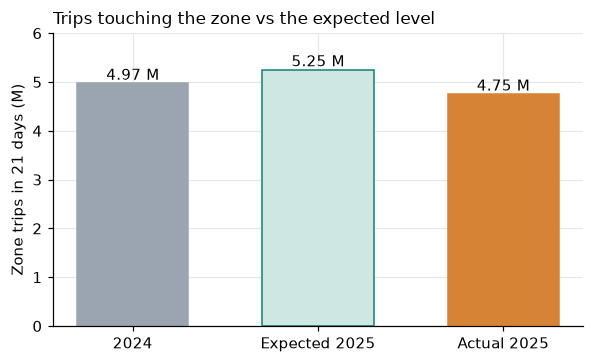

In [7]:
def window_trips(start, end):
    return daily[daily.request_date.between(start, end)].groupby("touches_zone").trips.sum()


before, after = window_trips("2024-01-08", "2024-01-28"), window_trips("2025-01-06", "2025-01-26")
outside_growth = after[False] / before[False] - 1
expected_zone = before[True] * (1 + outside_growth)
fee_gap = after[True] / expected_zone - 1

print(f"Outside the zone: {before[False] / 1e6:.2f} M -> {after[False] / 1e6:.2f} M trips ({outside_growth:+.1%})")
print(f"Zone, expected:   {before[True] / 1e6:.2f} M x {1 + outside_growth:.3f} = {expected_zone / 1e6:.2f} M")
print(f"Zone, actual:     {after[True] / 1e6:.2f} M -> gap vs expected {fee_gap:+.1%} "
      f"({(after[True] - expected_zone) / 1e6:+.2f} M trips)")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
bars = ax.bar(["2024", "Expected 2025", "Actual 2025"], [before[True] / 1e6, expected_zone / 1e6, after[True] / 1e6],
              color=[GREY, "#cfe7e3", ORANGE], edgecolor=[GREY, TEAL, ORANGE], width=0.6)
ax.bar_label(bars, fmt="%.2f M")
ax.set_ylim(0, 6)
ax.set_ylabel("Zone trips in 21 days (M)")
ax.set_title("Trips touching the zone vs the expected level")
plt.tight_layout()
plt.show()

### 2.2 Was the gap already there before the fee?

The method only works if the two groups moved together before the fee. 2–4 January 2025 had no fee yet, so the same gap on those days is a direct test. Each 2025 day is compared with the same weekday 364 days earlier.

Gap before the fee (2-4 Jan): -13.8%
Gap with the fee (6-26 Jan):  -9.5%


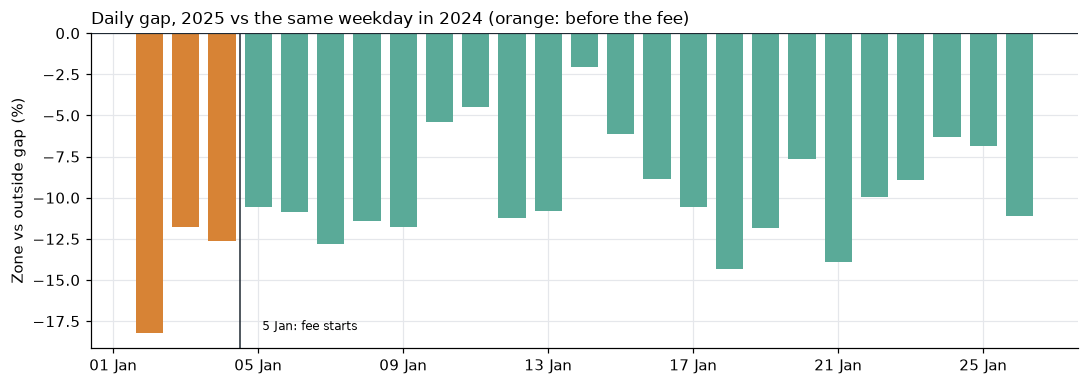

In [8]:
by_day = daily.pivot_table(index="request_date", columns="touches_zone", values="trips", aggfunc="sum")
gaps = pd.DataFrame({"date": pd.date_range("2025-01-02", "2025-01-26")})
gaps["prior_date"] = gaps.date - pd.Timedelta(days=364)
for year, dates in [("2025", gaps.date), ("2024", gaps.prior_date)]:
    gaps[f"zone_{year}"] = by_day.loc[dates, True].to_numpy()
    gaps[f"outside_{year}"] = by_day.loc[dates, False].to_numpy()
gaps["gap"] = (gaps.zone_2025 / gaps.zone_2024) / (gaps.outside_2025 / gaps.outside_2024) - 1


def pooled_gap(rows):
    s = rows[["zone_2025", "zone_2024", "outside_2025", "outside_2024"]].sum()
    return (s.zone_2025 / s.zone_2024) / (s.outside_2025 / s.outside_2024) - 1


pre_fee = pooled_gap(gaps[gaps.date < FEE_START])
with_fee = pooled_gap(gaps[gaps.date >= "2025-01-06"])
assert math.isclose(with_fee, fee_gap)
save(pd.DataFrame([{"gap_2_4_jan_before_fee": pre_fee, "gap_6_26_jan_with_fee": with_fee}]), "fee_pre_period_check")
print(f"Gap before the fee (2-4 Jan): {pre_fee:+.1%}")
print(f"Gap with the fee (6-26 Jan):  {with_fee:+.1%}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(gaps.date, 100 * gaps.gap, color=np.where(gaps.date < FEE_START, ORANGE, "#5aaa98"), width=0.75)
ax.axvline(FEE_START - pd.Timedelta(hours=12), color=INK, lw=1)
ax.text(FEE_START, 100 * gaps.gap.min(), " 5 Jan: fee starts", fontsize=8, va="bottom")
ax.axhline(0, color=INK, lw=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Zone vs outside gap (%)")
ax.set_title("Daily gap, 2025 vs the same weekday in 2024 (orange: before the fee)")
plt.tight_layout()
plt.show()

**Conclusion.** If the fee had reduced zone trips, the gap should have deepened after 5 January. It did the opposite: −13.8% before and −9.5% after. The −9.5% cannot be read as the effect of the fee. November–December 2024 data is needed to test this properly.

## 3. Was Lyft's credit worth it?

### 3.1 Effect on Lyft's share

Lyft gave a $1.50 credit on fee-paying rides from 5 to 31 January; Uber did not. If the credit worked, Lyft's **share of zone trips** should be higher while it ran than after it ended, relative to the same change outside the zone. Lyft share = Lyft trips ÷ (Uber + Lyft trips). Credit period: 6–26 Jan; after: 3–23 Feb (looked at in hindsight).

In [9]:
def lyft_share(start, end):
    t = daily[daily.request_date.between(start, end)].pivot_table(
        index="touches_zone", columns="operator", values="trips", aggfunc="sum")
    return t.Lyft / (t.Lyft + t.Uber)


share = pd.DataFrame({"with credit (6-26 Jan)": lyft_share("2025-01-06", "2025-01-26"),
                      "after credit (3-23 Feb)": lyft_share("2025-02-03", "2025-02-23")})
share["change"] = share.iloc[:, 1] - share.iloc[:, 0]
share.index = share.index.map({True: "touches zone (credit)", False: "outside zone (comparison)"})
share_gap = share.loc["outside zone (comparison)", "change"] - share.loc["touches zone (credit)", "change"]
uplift = share_gap / share.loc["touches zone (credit)", "after credit (3-23 Feb)"]
save(share.reset_index(), "credit_periods")
display(share.style.format("{:.1%}"))
print(f"Difference: {100 * share_gap:.1f} pp of share = about {uplift:.2%} more Lyft zone trips")

,with credit (6-26 Jan),after credit (3-23 Feb),change
touches_zone,,,
outside zone (comparison),23.9%,24.6%,0.7%
touches zone (credit),27.0%,26.1%,-0.9%


Difference: 1.6 pp of share = about 6.15% more Lyft zone trips


### 3.2 Cost per incremental trip

Take 100 normal Lyft trips. The credit adds *u* = 6.15 trips, but all 106.15 trips receive a $1.50 credit, not just the extra ones. Assumptions (not in public data): $6 contribution per trip and every credit redeemed.

In [10]:
def cost_per_extra_trip(uplift, credit=1.5, redemption=1.0, base=100):
    extra = base * uplift
    return (base + extra) * credit * redemption / extra


MARGIN, CREDIT = 6.0, 1.5
extra = 100 * uplift
steps = pd.DataFrame([
    ("1. Extra trips from the credit", f"100 x {uplift:.2%}", f"{extra:.2f} trips"),
    ("2. Credit paid out", f"{100 + extra:.2f} x ${CREDIT:.2f}", f"${(100 + extra) * CREDIT:.2f}"),
    ("3. Margin from the extra trips", f"{extra:.2f} x ${MARGIN:.0f}", f"${extra * MARGIN:.2f}"),
    ("4. Cost per extra trip", f"${(100 + extra) * CREDIT:.2f} / {extra:.2f}", f"${cost_per_extra_trip(uplift):.2f}"),
], columns=["step", "calculation", "result"])
display(steps.style.hide(axis="index"))

breakeven = CREDIT / (MARGIN - CREDIT)
print(f"Break-even uplift: {breakeven:.0%} more trips (observed: about {uplift:.0%})")
print(f"If only half of the credits are redeemed: ${cost_per_extra_trip(uplift, redemption=0.5):.2f} per extra trip")

step,calculation,result
1. Extra trips from the credit,100 x 6.15%,6.15 trips
2. Credit paid out,106.15 x $1.50,$159.23
3. Margin from the extra trips,6.15 x $6,$36.92
4. Cost per extra trip,$159.23 / 6.15,$25.88


Break-even uplift: 33% more trips (observed: about 6%)
If only half of the credits are redeemed: $12.94 per extra trip


**Conclusion.** The credit moved Lyft's share by 1.6 points, but each extra trip cost about $26 against a ~$6 margin. To break even the credit would need 33% more trips. This is an observational comparison; a test with a randomly held-out group of riders is needed to measure the real effect.

## 4. Weather and daily alerts

### 4.1 Effect of rain

Each rain hour is compared with dry, non-holiday hours of the same month, weekday and hour. Rain is grouped into light (0.5–2 mm/h) and heavy (> 2 mm/h); drizzle below 0.5 mm/h is left out and snow takes priority over rain.

January and February 2025 have only a few heavy-rain hours, so a summer window is used. It was picked from the 2024 weather record alone, before looking at trips: the three consecutive months with at least 20 heavy-rain hours and the most separate rain events.

In [11]:
def classify_weather(frame):
    frame = frame.sort_values("request_hour").copy()
    frame["weather"] = np.select(
        [frame.snowfall_cm > 0, frame.rain_mm > 2, frame.rain_mm >= 0.5, frame.rain_mm > 0],
        ["snow", "heavy rain", "light rain", "drizzle"], "dry")
    wet = (frame.rain_mm > 0) | (frame.snowfall_cm > 0)
    new_event = wet & (~wet.shift(fill_value=False) | frame.request_hour.diff().ne(pd.Timedelta(hours=1)))
    frame["event_id"] = new_event.cumsum().where(wet)
    frame["is_holiday"] = frame.request_hour.dt.normalize().isin(HOLIDAYS)
    for part in ("month", "dayofweek", "hour"):
        frame[part] = getattr(frame.request_hour.dt, part)
    return frame


year_2024 = classify_weather(fetch_weather("2024_full_year", "2024-01-01", "2024-12-31"))
heavy = year_2024[(year_2024.weather == "heavy rain") & ~year_2024.is_holiday]
windows = pd.DataFrame([{"months": f"{m:02d}-{m + 2:02d}",
                         "heavy_rain_hours": heavy.month.between(m, m + 2).sum(),
                         "rain_events": heavy[heavy.month.between(m, m + 2)].event_id.nunique()} for m in range(1, 11)])
chosen = windows[windows.heavy_rain_hours >= 20].sort_values(["rain_events", "heavy_rain_hours"], ascending=False).iloc[0]
first = int(chosen.months[:2])
RAIN_MONTHS = [f"2024-{m:02d}" for m in range(first, first + 3)]
print(f"Rain study window: {RAIN_MONTHS[0]} to {RAIN_MONTHS[-1]} "
      f"({chosen.heavy_rain_hours} heavy-rain hours in {chosen.rain_events} events)")
windows.set_index("months").T

Rain study window: 2024-06 to 2024-08 (35 heavy-rain hours in 14 events)


months,01-03,02-04,03-05,04-06,05-07,06-08,07-09,08-10,09-11,10-12
heavy_rain_hours,48,47,46,31,22,35,19,17,11,21
rain_events,9,9,8,10,9,14,8,7,3,5


weather,hours,rain_events,trips_factor,wait_factor
light rain,110,36,1.031,1.003
heavy rain,35,14,1.077,1.009


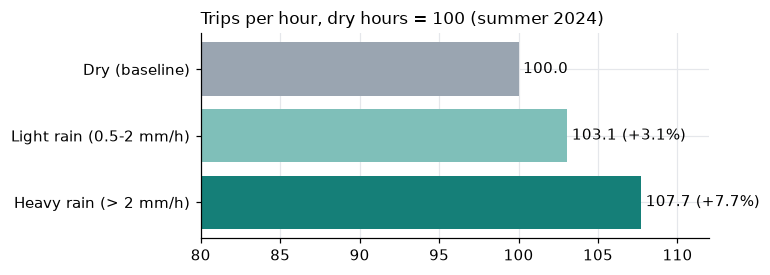

In [12]:
summer_files = [str(fetch_trips(m)) for m in RAIN_MONTHS]
summer = con.sql(f'''
    SELECT date_trunc('hour', request_datetime) AS request_hour,
           COUNT(*) AS trips,
           MEDIAN(CASE WHEN wait_min BETWEEN 0 AND 60 THEN wait_min END) AS median_wait
    FROM (
        SELECT request_datetime,
               date_diff('second', request_datetime, pickup_datetime) / 60.0 AS wait_min
        FROM read_parquet({summer_files}, union_by_name = true)
        WHERE hvfhs_license_num IN ('HV0003', 'HV0005')
          AND PULocationID IN (SELECT LocationID FROM known_zones)
          AND DOLocationID IN (SELECT LocationID FROM known_zones)
          AND request_datetime >= TIMESTAMP '{RAIN_MONTHS[0]}-01'
          AND request_datetime < TIMESTAMP '{RAIN_MONTHS[0]}-01' + INTERVAL 3 MONTH
    )
    GROUP BY request_hour
''').df().astype({"request_hour": "datetime64[ns]"})
summer_weather = pd.concat([fetch_weather(m, f"{m}-01", month_end(m)) for m in RAIN_MONTHS])
summer = classify_weather(summer.merge(summer_weather, on="request_hour", validate="one_to_one"))

keys = ["month", "dayofweek", "hour"]
dry = summer[(summer.weather == "dry") & ~summer.is_holiday]
base = dry.groupby(keys).agg(dry_trips=("trips", "median"), dry_wait=("median_wait", "median")).reset_index()
rain = summer[summer.weather.isin(["light rain", "heavy rain"]) & ~summer.is_holiday].merge(base, on=keys)
rain_factors = save(rain.assign(trip_ratio=rain.trips / rain.dry_trips, wait_ratio=rain.median_wait / rain.dry_wait)
                    .groupby("weather").agg(hours=("trip_ratio", "size"), rain_events=("event_id", "nunique"),
                                            trips_factor=("trip_ratio", "median"), wait_factor=("wait_ratio", "median"))
                    .loc[["light rain", "heavy rain"]].reset_index(), "rain_factors")
display(rain_factors.style.format({"trips_factor": "{:.3f}", "wait_factor": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(7, 2.6))
index = [100, *(100 * rain_factors.trips_factor)]
bars = ax.barh(["Dry (baseline)", "Light rain (0.5-2 mm/h)", "Heavy rain (> 2 mm/h)"], index, color=[GREY, "#7fbfb9", TEAL])
ax.bar_label(bars, [f"{v:.1f}" if i == 0 else f"{v:.1f} ({v - 100:+.1f}%)" for i, v in enumerate(index)], padding=3)
ax.set_xlim(80, 112)
ax.invert_yaxis()
ax.set_title("Trips per hour, dry hours = 100 (summer 2024)")
plt.tight_layout()
plt.show()

Heavy rain lifts trips by 7.7% while median wait barely moves (+0.9%). This is a summer relationship: it helps explain unusual days and plan extra drivers before rain, but it is not applied directly to the February forecast.

### 4.2 Alerting on unusual days

**Current rule.** Compare each segment-day with the mean of the same weekday one and two weeks earlier (or the same weekday a year earlier when those are missing) and alert when trips move more than ±7% or median wait more than ±20%.

In [13]:
def fixed_threshold_alerts(daily):
    table = daily.set_index(["request_date", "operator", "touches_zone"])[["trips", "median_wait"]]

    def lagged(days):
        shifted = table.copy()
        shifted.index = shifted.index.set_levels(shifted.index.levels[0] + pd.Timedelta(days=days), level=0)
        return shifted.reindex(table.index)

    d7, d14, d364 = lagged(7), lagged(14), lagged(364)
    two_weeks = d7.notna().all(axis=1) & d14.notna().all(axis=1)
    expected = (d7 + d14) / 2
    expected.loc[~two_weeks] = d364.loc[~two_weeks]
    deviation = table / expected - 1
    return deviation.trips.abs().gt(0.07) | deviation.median_wait.abs().gt(0.20)


fixed_alerts = fixed_threshold_alerts(daily)
print(f"Fixed ±7% rule: {fixed_alerts.sum()} alerts over 4 segments x 90 days")

Fixed ±7% rule: 118 alerts over 4 segments x 90 days


**New rule.** Measure how much each segment normally misses its two-week forecast (robust standard deviation of the log ratio, on days without holidays) and alert only beyond 2.5 times that. Holidays and 1–7 January are not used as reference days.

In [14]:
def band_alerts(table, k=2.5, floor=0.03):
    counts = table.set_index(["request_date", "operator", "touches_zone"]).trips
    usable = lambda d: d not in HOLIDAYS and not (d.month == 1 and d.day <= 7)
    rows = []
    for (day, operator, zone), actual in counts.items():
        refs = [day - pd.Timedelta(days=lag) for lag in (7, 14, 21, 28, 35)]
        refs = [d for d in refs if (d, operator, zone) in counts.index and usable(d)][:2]
        expected = np.mean([counts[(d, operator, zone)] for d in refs]) if refs else np.nan
        rows.append({"request_date": day, "operator": operator, "touches_zone": zone, "trips": actual,
                     "expected": expected, "references": refs, "is_holiday": day in HOLIDAYS})
    out = pd.DataFrame(rows)
    out["log_ratio"] = np.log(out.trips / out.expected)
    calibration = out[~out.is_holiday & (out.references.str.len() == 2)]
    stats = calibration.groupby(["operator", "touches_zone"]).log_ratio.agg(
        center="median", robust_sd=lambda x: 1.4826 * (x - x.median()).abs().median()).reset_index()
    out = out.merge(stats, on=["operator", "touches_zone"])
    scale = np.where(out.references.str.len() == 1, math.sqrt(4 / 3), 1.0)
    out["alert"] = (out.log_ratio - out.center).abs() > np.maximum(k * out.robust_sd, math.log(1 + floor)) * scale
    return out, stats


band, band_stats = band_alerts(daily)
save(band.assign(references=band.references.map(lambda refs: ",".join(f"{d:%Y-%m-%d}" for d in refs))), "forecast_band_alerts")
display(band_stats.assign(segment=[segment_name(o, z) for o, z in zip(band_stats.operator, band_stats.touches_zone)])
        [["segment", "robust_sd"]].style.format({"robust_sd": "{:.1%}"}).hide(axis="index"))
print(f"Forecast band (2.5 x robust SD): {band.alert.sum()} alerts")

segment,robust_sd
Lyft outside,6.2%
Lyft zone,6.4%
Uber outside,4.8%
Uber zone,6.5%


Forecast band (2.5 x robust SD): 9 alerts


Each alert is checked against the two things an analyst looks at first: is the day a holiday, and did a reference day have at least 3 hours of rain or snow (which pushes the expected value up or down)?

In [15]:
day_weather = weather.assign(request_date=weather.request_hour.dt.normalize()).groupby("request_date").agg(
    rain_hours=("rain_mm", lambda x: int((x >= 0.5).sum())), snow_hours=("snowfall_cm", lambda x: int((x > 0).sum())))
wet_day = (day_weather.rain_hours + day_weather.snow_hours) >= 3


def explain(row):
    if row.is_holiday:
        return f"holiday: {HOLIDAYS[row.request_date]}"
    if any(wet_day[d] for d in row.references):
        return "rain or snow on a reference day"
    return "unexplained: investigate"


alerts = band[band.alert].copy()
alerts["references"] = alerts.references.map(lambda refs: ", ".join(
    f"{d:%d %b} (rain {day_weather.rain_hours[d]}h, snow {day_weather.snow_hours[d]}h)" for d in refs))
alerts["reason"] = band[band.alert].apply(explain, axis=1)
display(alerts[["request_date", "operator", "touches_zone", "trips", "expected", "references", "reason"]]
        .style.format({"request_date": "{:%d %b %Y}", "trips": "{:,.0f}", "expected": "{:,.0f}"}).hide(axis="index"))
alerts.reason.str.split(":").str[0].value_counts()

request_date,operator,touches_zone,trips,expected,references,reason
15 Jan 2024,Lyft,True,"50,171","40,718","08 Jan (rain 0h, snow 0h)",holiday: Martin Luther King Jr. Day
15 Jan 2024,Uber,True,"150,028","119,767","08 Jan (rain 0h, snow 0h)",holiday: Martin Luther King Jr. Day
17 Jan 2024,Uber,False,"316,435","267,023","10 Jan (rain 4h, snow 0h)",rain or snow on a reference day
17 Jan 2024,Uber,True,"185,352","147,417","10 Jan (rain 4h, snow 0h)",rain or snow on a reference day
23 Jan 2024,Lyft,False,"96,470","113,670","16 Jan (rain 1h, snow 18h), 09 Jan (rain 10h, snow 0h)",rain or snow on a reference day
27 Jan 2024,Lyft,False,"117,541","133,649","20 Jan (rain 0h, snow 0h), 13 Jan (rain 7h, snow 0h)",rain or snow on a reference day
15 Jan 2025,Lyft,False,"92,806","114,609","08 Jan (rain 0h, snow 0h)",unexplained: investigate
23 Feb 2025,Uber,True,"146,797","171,958","16 Feb (rain 17h, snow 0h), 09 Feb (rain 3h, snow 9h)",rain or snow on a reference day
28 Feb 2025,Uber,True,"160,228","186,752","21 Feb (rain 0h, snow 0h), 14 Feb (rain 0h, snow 0h)",unexplained: investigate


reason
rain or snow on a reference day    5
holiday                            2
unexplained                        2
Name: count, dtype: int64

**Conclusion.** Each segment normally moves 5–6% a day, so a ±7% threshold fires constantly (118 alerts in three months, mostly false). The segment-specific band raises 9: 2 are MLK Day 2024, 5 had rain or snow on a reference day, and 2 remain unexplained. Fewer false alarms means the team acts on each one.

## 5. Forecast for 17–23 February 2025

### 5.1 Information available at the cutoff

The plan is made at the end of 16 February, so history only includes trips **completed** before midnight: a trip requested late on 16 February that ends on the 17th is left out.

In [16]:
history = con.sql('''
    SELECT request_date, operator, touches_zone, COUNT(*) AS trips
    FROM labeled
    WHERE request_date BETWEEN DATE '2025-01-01' AND DATE '2025-02-16'
      AND dropoff_datetime < TIMESTAMP '2025-02-17'
    GROUP BY request_date, operator, touches_zone
''').df()
history["request_date"] = pd.to_datetime(history.request_date).astype("datetime64[ns]")
known = history.set_index(["request_date", "operator", "touches_zone"]).trips
final = daily[daily.request_date <= CUTOFF].set_index(["request_date", "operator", "touches_zone"]).trips
assert known.index.get_level_values(0).max() == CUTOFF
print(f"Trips completed after the cutoff and left out: {int((final - known.reindex(final.index)).sum()):,}")

Trips completed after the cutoff and left out: 9,961


### 5.2 Three simple methods

| Method | Forecast for day *D* in each segment |
|---|---|
| **B1** | trips on *D* − 7 |
| **B2** | mean of *D* − 7 and *D* − 14 |
| **B3** | B2, with 17 Feb multiplied by the segment's MLK factor: trips on 20 Jan ÷ mean of 13 and 27 Jan |

**B2 is chosen before scoring**, because averaging two weeks keeps one unusual day from pulling the plan. Each of the 4 segments is forecast for each of the 7 days, then summed.

In [17]:
def holiday_week_forecast(known):
    rows = []
    for operator, zone in SEGMENTS:
        at = lambda day: known[(pd.Timestamp(day), operator, zone)]
        mlk_factor = at("2025-01-20") / ((at("2025-01-13") + at("2025-01-27")) / 2)
        for day in pd.date_range("2025-02-17", "2025-02-23"):
            b1 = at(day - pd.Timedelta(days=7))
            b2 = (b1 + at(day - pd.Timedelta(days=14))) / 2
            rows.append({"request_date": day, "operator": operator, "touches_zone": zone, "B1": b1, "B2": b2,
                         "B3": b2 * (mlk_factor if day == pd.Timestamp("2025-02-17") else 1.0)})
    return pd.DataFrame(rows)


forecast = save(holiday_week_forecast(known), "forecast_week")

city_known = known.groupby(level="request_date").sum()
d7, d14 = city_known[pd.Timestamp("2025-02-15")], city_known[pd.Timestamp("2025-02-08")]
print(f"Example, Saturday 22 Feb: ({d7:,} + {d14:,}) / 2 = {(d7 + d14) / 2:,.1f} ≈ {math.floor((d7 + d14) / 2 + 0.5):,} trips")
print(f"B2 plan for 17-23 Feb: {forecast.B2.sum():,.0f} trips")

Example, Saturday 22 Feb: (817,635 + 780,902) / 2 = 799,268.5 ≈ 799,269 trips
B2 plan for 17-23 Feb: 4,871,468 trips


### 5.3 Forecast vs actual

WAPE = Σ|forecast − actual| ÷ Σ actual over all 28 cells (7 days × 4 segments). Bias = Σ(forecast − actual) ÷ Σ actual.

method,absolute_error,actual_trips,WAPE,bias
B1,"214,483","4,820,140",4.4%,+2.7%
B2,"167,950","4,820,140",3.5%,+1.1%
B3,"174,148","4,820,140",3.6%,+1.0%


Week: plan 4.87 M, actual 4.82 M, plan +1.1% vs actual


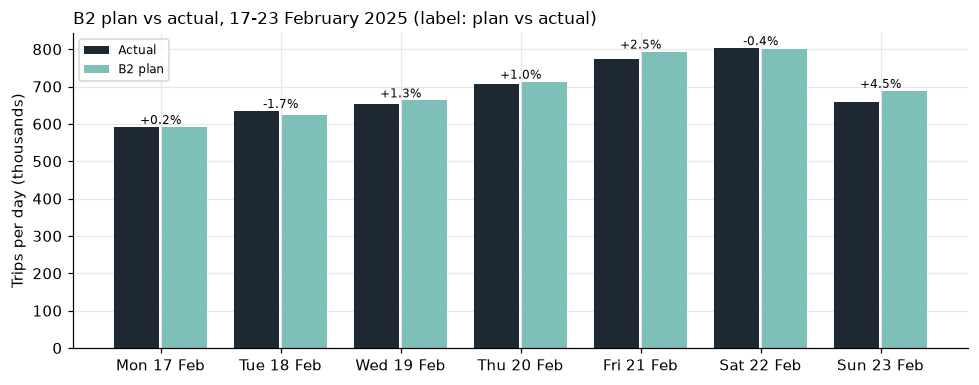

In [18]:
actual = daily[daily.request_date.between("2025-02-17", "2025-02-23")][["request_date", "operator", "touches_zone", "trips"]]
scored = forecast.merge(actual, on=["request_date", "operator", "touches_zone"], validate="one_to_one")
assert len(scored) == 28

scores = save(pd.DataFrame([{"method": m,
                             "absolute_error": (scored[m] - scored.trips).abs().sum(),
                             "actual_trips": scored.trips.sum(),
                             "WAPE": (scored[m] - scored.trips).abs().sum() / scored.trips.sum(),
                             "bias": (scored[m] - scored.trips).sum() / scored.trips.sum()}
                            for m in ("B1", "B2", "B3")]), "forecast_scores")
display(scores.style.format({"absolute_error": "{:,.0f}", "actual_trips": "{:,.0f}", "WAPE": "{:.1%}", "bias": "{:+.1%}"})
        .hide(axis="index"))

by_day = scored.groupby("request_date")[["trips", "B2"]].sum()
by_day["plan_vs_actual"] = by_day.B2 / by_day.trips - 1
print(f"Week: plan {by_day.B2.sum() / 1e6:.2f} M, actual {by_day.trips.sum() / 1e6:.2f} M, "
      f"plan {by_day.B2.sum() / by_day.trips.sum() - 1:+.1%} vs actual")

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(by_day))
ax.bar(x - 0.2, by_day.trips / 1e3, 0.38, color=INK, label="Actual")
ax.bar(x + 0.2, by_day.B2 / 1e3, 0.38, color="#7fbfb9", label="B2 plan")
for i, (top, gap) in enumerate(zip(by_day[["trips", "B2"]].max(axis=1), by_day.plan_vs_actual)):
    ax.text(i, top / 1e3 + 8, f"{gap:+.1%}", ha="center", fontsize=8)
ax.set_xticks(x, by_day.index.strftime("%a %d %b"))
ax.set_ylabel("Trips per day (thousands)")
ax.set_title("B2 plan vs actual, 17-23 February 2025 (label: plan vs actual)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

The largest miss is Sunday 23 February. Both of its reference days had rain or snow, while 23 February itself was dry:

In [19]:
day_weather.loc[pd.to_datetime(["2025-02-09", "2025-02-16", "2025-02-23"])]

,rain_hours,snow_hours
2025-02-09,3,9
2025-02-16,17,0
2025-02-23,0,0


**Conclusion.** B2 planned 4.87 M trips against 4.82 M actual (+1.1%), with a WAPE of 3.5%, better than last week alone (B1, 4.4%). This is one test week, so it supports the method but does not prove it always wins.

## 6. Recommendations at the planning date (16 February 2025)

| # | Recommendation | Why |
|---|---|---|
| 1 | **Plan 4.87 M trips** for 17–23 Feb with B2; watch the 17 Feb holiday separately and keep a plan for rain or snow | B2 averages out one unusual day; weather on reference days is the main source of error |
| 2 | **Do not give the credit to everyone.** Test it on selected riders, hold out 10% at random, run at least 14 days, and measure redemption | $25.88 per extra trip against ~$6 margin; break-even needs 33% more trips |
| 3 | **Switch to the segment-specific alert band** and get Nov–Dec 2024 data before measuring the fee again | 118 → 9 alerts; the fee gap existed before the fee |

**Limits.** TLC records completed trips only, so cancelled requests, driver supply, rider IDs, credit redemption and margins are not observed. All effects are observational.